<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Normalized fields are not verified contacts

**How much can offline validation improve a contact import, and where does country context matter?**
We will retain every input row, distinguish missing from invalid values, and normalize
email, phone and URL fields through the real VGI worker. SQL will show which strings
collapse to the same representation and which deliberately remain different.

These twelve records are **synthetic teaching inputs**, not a contact list. No email,
phone or URL is contacted. Passing a format check does not establish reachability,
ownership or identity; equal normalized fields do not prove two rows are one person.

## Choose the phone context

`PHONE_CONTEXT` accepts `"row_country"` (default) or `"US"` (experiment).
The default uses each record's explicit US/GB parsing context. The experiment applies
US to every number. Both alternatives are calculated for comparison; this parameter
selects the main field report. The raw strings and email/URL checks stay fixed.
Restart the kernel and run all after changing it. [Setup instructions](README.md).

In [1]:
PHONE_CONTEXT = "row_country"

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p
    for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file()
)
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle
from notebook_support import finish, prose, theme

if PHONE_CONTEXT not in {"row_country", "US"}:
    raise ValueError('PHONE_CONTEXT must be "row_country" or "US".')
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-conform/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-conform/notebooks/pyproject.toml.

## Connect to the published worker

This literal `uvx` command retrieves the tagged worker and pins its validation libraries
and VGI runtime. Initial installation needs network access; the checks below are offline.
The small discovery query confirms the two supported parsing contexts used in our inputs.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'conform' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --with phonenumbers==9.0.43 --with python-stdnum==2.2 --with email-validator==2.3.0 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --from git+https://github.com/Query-farm/vgi-conform@v0.4.0 vgi-conform-worker');
SELECT * FROM conform.main.supported_phone_regions()
WHERE region IN ('US', 'GB') ORDER BY region;

,region,country_code
0,GB,44
1,US,1


## Keep the raw evidence

The rows include domain/scheme case changes, local-part and URL-path case differences,
national and international phone forms, malformed strings, empty strings and SQL NULL.
`country` is a supplied parsing context, not inferred residence. The German international
number on a US-labelled row will let us distinguish parsing context from returned number region.

In [5]:
%%sql
CREATE OR REPLACE TABLE contacts AS
SELECT * FROM (VALUES
 (1, 'US', 'Ann@Example.COM', '202-555-0100', 'HTTP://Example.com:80/Path'),
 (2, 'US', 'Ann@example.com', '(202) 555-0100', 'http://example.com/Path'),
 (3, 'US', 'ann@example.com', '+1 202 555 0100', 'http://example.com/path'),
 (4, 'GB', 'Bea@Example.ORG', '07400 123456', 'https://EXAMPLE.org:443/Start'),
 (5, 'GB', 'Bea@example.org', '+44 7400 123456', 'https://example.org/Start'),
 (6, 'US', 'Cal@example.net', '+49 30 901820', 'https://example.net/'),
 (7, 'GB', 'Dana@bücher.de', '020 7946 0958', 'HTTPS://Example.org:443/Docs?b=2&a=1#intro'),
 (8, 'US', 'Eve@example.com', NULL, NULL),
 (9, 'US', 'not-an-email', '12345', 'example.com'),
 (10, 'GB', '', '', ''),
 (11, 'US', NULL, NULL, NULL),
 (12, 'GB', 'dana@bücher.de', '+44 20 7946 0958', 'https://example.org/Docs?a=1&b=2#intro')
) AS t(record_id, country, email, phone, url);
SELECT * FROM contacts ORDER BY record_id;

,record_id,country,email,phone,url
0,1,US,Ann@Example.COM,202-555-0100,HTTP://Example.com:80/Path
1,2,US,Ann@example.com,(202) 555-0100,http://example.com/Path
2,3,US,ann@example.com,+1 202 555 0100,http://example.com/path
3,4,GB,Bea@Example.ORG,07400 123456,https://EXAMPLE.org:443/Start
4,5,GB,Bea@example.org,+44 7400 123456,https://example.org/Start
5,6,US,Cal@example.net,+49 30 901820,https://example.net/
6,7,GB,Dana@bücher.de,020 7946 0958,HTTPS://Example.org:443/Docs?b=2&a=1#intro
7,8,US,Eve@example.com,None,None
8,9,US,not-an-email,12345,example.com
9,10,GB,,,


## Validate first, then normalize

A missing raw value stays **missing**. A nonmissing value that fails validation is
**invalid**, including empty text. Only valid values are classified as unchanged or
normalized. We retain both the original and normalized string, so no failed value
is silently replaced with a plausible-looking value.

The released phone overloads require a **constant region argument**. These explicit
US/GB branches supply constants while selecting the branch from each row. The guard
rejects new country values until a supported branch is added. International `+` numbers
carry their own calling code; the supplied region matters for national forms.

In [6]:
%%sql
SELECT CASE WHEN count(*) FILTER (WHERE country IS NULL OR country NOT IN ('US','GB')) = 0
 THEN 'Every record has a supported branch' ELSE error('Add an explicit country branch first') END AS context_check
FROM contacts;
CREATE OR REPLACE TABLE common_fields AS
SELECT record_id, 'Email' AS field, email AS raw_value,
 conform.main.is_valid_email(email) AS valid,
 conform.main.normalize_email(email) AS normalized FROM contacts
UNION ALL
SELECT record_id, 'URL', url, conform.main.is_valid_url(url),
 conform.main.normalize_url(url) FROM contacts;
CREATE OR REPLACE TABLE phone_results AS
SELECT record_id, 'row_country' AS context, country, phone AS raw_value,
 CASE country WHEN 'US' THEN conform.main.is_valid_phone(phone,'US')
              WHEN 'GB' THEN conform.main.is_valid_phone(phone,'GB') END AS valid,
 CASE country WHEN 'US' THEN conform.main.format_phone_e164(phone,'US')
              WHEN 'GB' THEN conform.main.format_phone_e164(phone,'GB') END AS normalized,
 CASE country WHEN 'US' THEN conform.main.phone_region(phone,'US')
              WHEN 'GB' THEN conform.main.phone_region(phone,'GB') END AS number_region
FROM contacts
UNION ALL
SELECT record_id, 'US', country, phone,
 conform.main.is_valid_phone(phone,'US'), conform.main.format_phone_e164(phone,'US'),
 conform.main.phone_region(phone,'US') FROM contacts;
CREATE OR REPLACE TABLE all_fields AS
SELECT context, record_id, field, raw_value, valid, normalized FROM common_fields
CROSS JOIN (VALUES ('row_country'),('US')) AS contexts(context)
UNION ALL
SELECT context, record_id, 'Phone', raw_value, valid, normalized FROM phone_results;
CREATE OR REPLACE TABLE classified AS
SELECT *, CASE WHEN raw_value IS NULL THEN 'Missing'
 WHEN NOT valid THEN 'Invalid'
 WHEN raw_value = normalized THEN 'Valid · unchanged'
 ELSE 'Valid · normalized' END AS status FROM all_fields;

,Count


In [7]:
%%sql report <<
SELECT record_id, field, raw_value, normalized, status
FROM classified WHERE context = '{{ PHONE_CONTEXT }}'
ORDER BY record_id, field;

In [8]:
report = globals()["report"]
display(report)
prose(
    f"All **{report.record_id.nunique()} records** remain in the report, with "
    f"**{len(report)} field observations**. Missing and invalid values remain visible "
    "instead of disappearing in a `WHERE valid` filter."
)

,record_id,field,raw_value,normalized,status
0,1,Email,Ann@Example.COM,Ann@example.com,Valid · normalized
1,1,Phone,202-555-0100,+12025550100,Valid · normalized
2,1,URL,HTTP://Example.com:80/Path,http://example.com/Path,Valid · normalized
3,2,Email,Ann@example.com,Ann@example.com,Valid · unchanged
4,2,Phone,(202) 555-0100,+12025550100,Valid · normalized
5,2,URL,http://example.com/Path,http://example.com/Path,Valid · unchanged
6,3,Email,ann@example.com,ann@example.com,Valid · unchanged
7,3,Phone,+1 202 555 0100,+12025550100,Valid · normalized
8,3,URL,http://example.com/path,http://example.com/path,Valid · unchanged
9,4,Email,Bea@Example.ORG,Bea@example.org,Valid · normalized


All **12 records** remain in the report, with **36 field observations**. Missing and invalid values remain visible instead of disappearing in a `WHERE valid` filter.

## What changed in the import?

Count all four outcomes on a shared row-count scale. Every field has the same denominator;
normalization means the returned string changed, not that an invalid field was repaired.

**Release limitation:** the pinned v0.4.0 worker rejects `https://example.net/`
(record 06), although it is an absolute URL. Here, “Invalid” records the worker’s
verdict, not a universal URL rule. Its URL parser treats this root-path case
differently from the nonempty paths in the other examples; keep the raw value
for review rather than discarding it.

In [9]:
%%sql quality <<
SELECT field, status, count(*) AS records
FROM classified WHERE context = '{{ PHONE_CONTEXT }}'
GROUP BY field, status ORDER BY field, status;

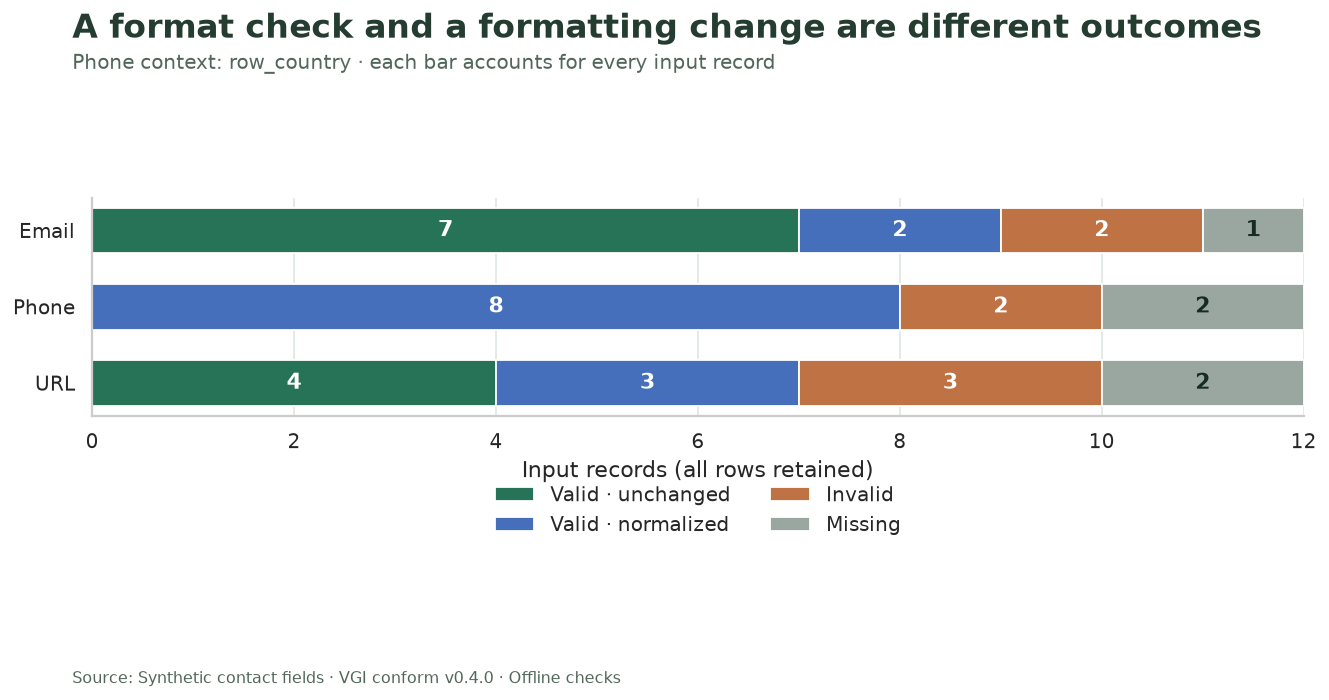

With **row_country** phone context, **8 of 12** phone fields pass. Empty strings are invalid; NULL is missing. No normalized value is substituted for either state.

In [10]:
quality = globals()["quality"]
statuses = ["Valid · unchanged", "Valid · normalized", "Invalid", "Missing"]
colors = ["#267358", "#456fba", "#bf7345", "#9aa7a0"]
counts = (
    quality.pivot(index="field", columns="status", values="records")
    .reindex(index=["Email", "Phone", "URL"], columns=statuses)
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(10.6, 5.4))
left = np.zeros(len(counts))
for status, color in zip(statuses, colors):
    values = counts[status].to_numpy()
    ax.barh(counts.index, values, left=left, color=color, label=status, height=0.6)
    for y, (start, value) in enumerate(zip(left, values)):
        if value:
            ax.text(
                start + value / 2,
                y,
                str(int(value)),
                ha="center",
                va="center",
                color="white" if status != "Missing" else "#162b21",
                weight="bold",
            )
    left += values
ax.set_xlim(0, report.record_id.nunique())
ax.set_xticks(np.arange(0, report.record_id.nunique() + 1, 2))
ax.set_xlabel("Input records (all rows retained)")
ax.set_ylabel("")
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), ncol=2, frameon=False)
finish(
    fig,
    "A format check and a formatting change are different outcomes",
    f"Phone context: {PHONE_CONTEXT} · each bar accounts for every input record",
    f"field-quality-{PHONE_CONTEXT}.png",
)
phone_valid = int(counts.loc["Phone", statuses[:2]].sum())
prose(
    f"With **{PHONE_CONTEXT}** phone context, **{phone_valid} of {report.record_id.nunique()}** "
    "phone fields pass. Empty strings are invalid; NULL is missing. "
    "No normalized value is substituted for either state."
)

## Equal representations do not establish identity

Compare distinct raw and normalized strings **among valid values**, then inspect the groups
that collapse. Email domains are normalized while local-part case is retained. URL scheme,
host and default port are normalized; path case, query order and fragment remain as supplied.
These groups are candidates for field-level matching, not automatic person merges.

In [11]:
%%sql uniqueness <<
SELECT field, count(*) FILTER (WHERE valid) AS valid_rows,
 count(DISTINCT raw_value) FILTER (WHERE valid) AS distinct_raw_valid,
 count(DISTINCT normalized) AS distinct_normalized
FROM classified WHERE context = '{{ PHONE_CONTEXT }}' GROUP BY field ORDER BY field;

In [12]:
uniqueness = globals()["uniqueness"]
display(uniqueness)
prose(
    "Distinct counts use only valid strings; they exclude failed and missing values. "
    "The next table keeps the record IDs and raw variants behind every repeated normalized value."
)

,field,valid_rows,distinct_raw_valid,distinct_normalized
0,Email,9,9,7
1,Phone,8,8,4
2,URL,7,7,5


Distinct counts use only valid strings; they exclude failed and missing values. The next table keeps the record IDs and raw variants behind every repeated normalized value.

In [13]:
%%sql
SELECT field, normalized, list(record_id ORDER BY record_id) AS records,
 list(DISTINCT raw_value ORDER BY raw_value) AS raw_variants
FROM classified WHERE context = '{{ PHONE_CONTEXT }}' AND valid
GROUP BY field, normalized HAVING count(*) > 1 ORDER BY field, normalized;

,field,normalized,records,raw_variants
0,Email,Ann@example.com,"[1, 2]","[Ann@Example.COM, Ann@example.com]"
1,Email,Bea@example.org,"[4, 5]","[Bea@Example.ORG, Bea@example.org]"
2,Phone,+12025550100,"[1, 2, 3]","[(202) 555-0100, +1 202 555 0100, 202-555-0100]"
3,Phone,+442079460958,"[7, 12]","[+44 20 7946 0958, 020 7946 0958]"
4,Phone,+447400123456,"[4, 5]","[+44 7400 123456, 07400 123456]"
5,URL,http://example.com/Path,"[1, 2]","[HTTP://Example.com:80/Path, http://example.co..."
6,URL,https://example.org/Start,"[4, 5]","[https://EXAMPLE.org:443/Start, https://exampl..."


## Country context changes national phone parsing

Compare both contexts without changing the source values. Each cell reports the worker's
validity result; empty and missing inputs remain separate. A valid result still does not
prove the number is assigned or reachable. The orange outline marks the currently selected
context used in the earlier report.

In [14]:
%%sql context_rows <<
SELECT record_id, country, raw_value, context,
 CASE WHEN raw_value IS NULL THEN 'Missing' WHEN valid THEN 'Valid' ELSE 'Invalid' END AS status,
 normalized, number_region
FROM phone_results ORDER BY record_id, context;

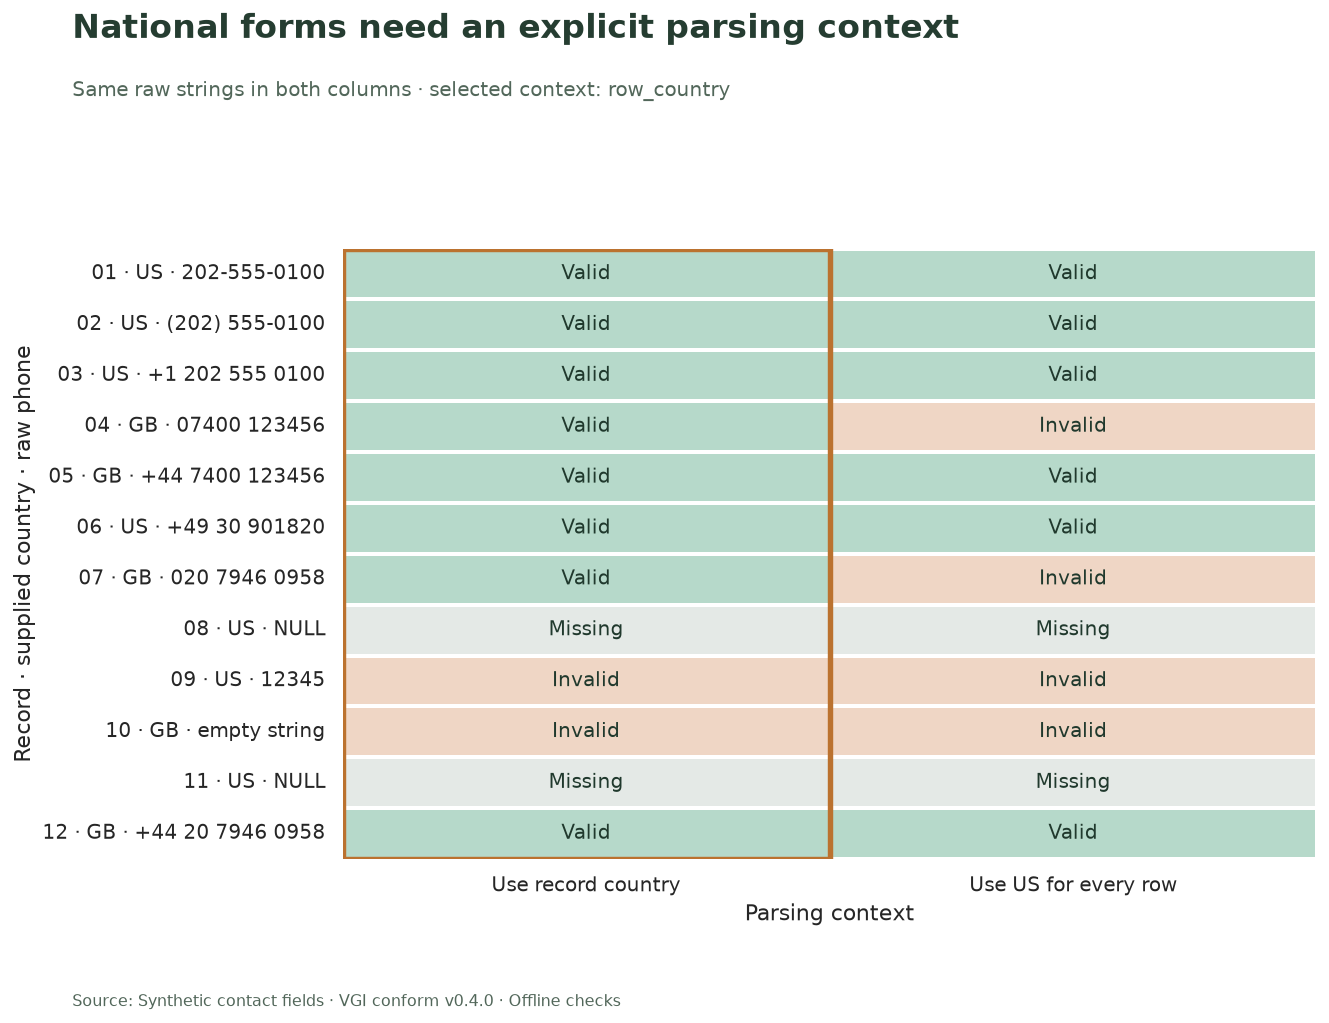

Using row country gives **8 valid phone fields**; using US gives **6**. **2 records** change status. Those differences come from the supplied parsing context, not a change in the raw number.

In [15]:
context_rows = globals()["context_rows"]
contexts = ["row_country", "US"]
phone_matrix = context_rows.pivot(index="record_id", columns="context", values="status")[contexts]
number = {"Invalid": 0, "Missing": 1, "Valid": 2}
values = phone_matrix.map(number.__getitem__)
labels = context_rows[context_rows.context == "row_country"].set_index("record_id")
ylabels = [
    f"{i:02d} · {labels.loc[i, 'country']} · "
    + (
        "NULL"
        if labels.loc[i, "raw_value"] is None
        else "empty string"
        if labels.loc[i, "raw_value"] == ""
        else labels.loc[i, "raw_value"]
    )
    for i in phone_matrix.index
]
fig, ax = plt.subplots(figsize=(10.6, 8))
sns.heatmap(
    values,
    annot=phone_matrix,
    fmt="",
    cmap=ListedColormap(["#efd6c5", "#e4e9e6", "#b6d9ca"]),
    vmin=-0.5,
    vmax=2.5,
    cbar=False,
    linewidths=2,
    linecolor="white",
    ax=ax,
    annot_kws={"fontsize": 11, "color": "#20392d"},
)
ax.set_yticklabels(ylabels, rotation=0)
ax.set_xticklabels(["Use record country", "Use US for every row"], rotation=0)
ax.set_xlabel("Parsing context")
ax.set_ylabel("Record · supplied country · raw phone")
ax.add_patch(
    Rectangle(
        (contexts.index(PHONE_CONTEXT), 0),
        1,
        len(values),
        fill=False,
        edgecolor="#bb722f",
        linewidth=3,
    )
)
finish(
    fig,
    "National forms need an explicit parsing context",
    f"Same raw strings in both columns · selected context: {PHONE_CONTEXT}",
    f"phone-context-{PHONE_CONTEXT}.png",
)
valid_by_context = context_rows.groupby("context").status.apply(lambda s: int((s == "Valid").sum()))
changed = int((phone_matrix.row_country != phone_matrix.US).sum())
prose(
    f"Using row country gives **{valid_by_context['row_country']} valid phone fields**; "
    f"using US gives **{valid_by_context['US']}**. **{changed} records** change status. "
    "Those differences come from the supplied parsing context, not a change in the raw number."
)

A number's returned region is a separate attribute. Keep disagreements visible for review;
a supplied country might describe residence, office location or a data-entry assumption,
so a mismatch is not itself proof of invalidity.

In [16]:
%%sql
SELECT record_id, country AS supplied_country, raw_value, normalized AS e164,
 number_region, country = number_region AS same_region
FROM phone_results
WHERE context = '{{ PHONE_CONTEXT }}' AND valid AND country <> number_region
ORDER BY record_id;

,record_id,supplied_country,raw_value,e164,number_region,same_region
0,6,US,+49 30 901820,+4930901820,DE,False


## Check the transformation contract

These checks cover row conservation, three-valued validity, idempotent normalization,
context-independent fields and preservation of international `+` forms. They do not
assert a particular success rate or require a particular contact to pass.

In [17]:
%%sql checks <<
SELECT 'Every record has each field under both contexts' AS check_name,
 abs((SELECT count(*) FROM classified) - (SELECT count(*) * 6 FROM contacts))
 + (SELECT count(*) FROM (SELECT context,record_id,field,count(*) AS n
                         FROM classified GROUP BY ALL HAVING n <> 1)) AS violations
UNION ALL
SELECT 'Missing raw values keep NULL validity and normalization', count(*)
FROM classified WHERE raw_value IS NULL AND (valid IS NOT NULL OR normalized IS NOT NULL)
UNION ALL
SELECT 'Nonmissing validity agrees with normalized availability', count(*)
FROM classified WHERE raw_value IS NOT NULL AND
 (valid IS NULL OR valid IS DISTINCT FROM (normalized IS NOT NULL))
UNION ALL
SELECT 'Email and URL normalization is idempotent', count(*) FROM common_fields
WHERE valid AND normalized IS DISTINCT FROM
 CASE field WHEN 'Email' THEN conform.main.normalize_email(normalized)
            WHEN 'URL' THEN conform.main.normalize_url(normalized) END
UNION ALL
SELECT 'E.164 normalization is idempotent', count(*) FROM phone_results
WHERE valid AND normalized IS DISTINCT FROM conform.main.format_phone_e164(normalized,'US')
UNION ALL
SELECT 'Email and URL results do not depend on phone context', count(*)
FROM classified a JOIN classified b USING(record_id,field)
WHERE a.context='row_country' AND b.context='US' AND a.field <> 'Phone'
 AND (a.normalized IS DISTINCT FROM b.normalized OR a.valid IS DISTINCT FROM b.valid)
UNION ALL
SELECT 'Explicit international numbers agree across contexts', count(*)
FROM phone_results a JOIN phone_results b USING(record_id)
WHERE a.context='row_country' AND b.context='US' AND starts_with(a.raw_value,'+')
 AND (a.normalized IS DISTINCT FROM b.normalized OR a.valid IS DISTINCT FROM b.valid)
UNION ALL
SELECT 'Normalized cardinality never exceeds raw valid cardinality', count(*)
FROM (SELECT context,field,count(DISTINCT normalized) AS norm_n,
 count(DISTINCT raw_value) FILTER(WHERE valid) AS raw_n
 FROM classified GROUP BY context,field) WHERE norm_n > raw_n;

In [18]:
checks = globals()["checks"]
display(checks)
assert (checks.violations == 0).all(), "A transformation contract check failed."
prose(
    f"All **{len(checks)} checks** pass. These establish behavior for the supplied fixture "
    "and pinned libraries; they do not validate deliverability, ownership or identity."
)

,check_name,violations
0,Every record has each field under both contexts,0
1,Missing raw values keep NULL validity and norm...,0
2,Nonmissing validity agrees with normalized ava...,0
3,Email and URL normalization is idempotent,0
4,E.164 normalization is idempotent,0
5,Email and URL results do not depend on phone c...,0
6,Explicit international numbers agree across co...,0
7,Normalized cardinality never exceeds raw valid...,0


All **8 checks** pass. These establish behavior for the supplied fixture and pinned libraries; they do not validate deliverability, ownership or identity.

## One change to try

Predict which rows will change before setting `PHONE_CONTEXT = "US"` and running all cells.
Compare the Phone bar, the raw-to-normalized report and the outlined column of the context
matrix. The two national GB strings should lose their usable normalized value under this
assumption; the explicit international forms should agree. Email and URL results should
remain identical. Reset to `"row_country"` afterward.

To preserve the saved default, run a separate executed copy:

```sh
uv run --locked python execute.py --parameters '{"PHONE_CONTEXT":"US"}' \
  --output-dir validation/us-context
```

For an import pipeline, retain raw values and validation outcomes, choose documented
country context, and review possible matches using evidence beyond a normalized field.
The worker also exposes postal, IBAN, VAT and card checks; those need their own country,
format and checksum assumptions. This walkthrough deliberately stays with contact fields.

In [19]:
con.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)